In [1]:
import matplotlib.pyplot as plt
import random as r
import numpy as np
import configparser
import torch

from pathlib import Path
from extractor import extract_mel_spectrogram
from tokenizer import mel_tokenizer

ROOT = Path.cwd()

In [2]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

## Single Mel Spectrogram

In [3]:
while not (ROOT / "datasets").exists():
    ROOT = ROOT.parent
dataset_path = ROOT / "datasets" / "fma" / "fma_large"
audio_files = list(dataset_path.rglob("*.mp3"))
print(f"Total Files Found : {len(audio_files)}")

Total Files Found : 106574


In [4]:
audio_path = r.choice(audio_files)

In [5]:
mel = extract_mel_spectrogram(audio_path)

In [6]:
print(mel.shape)

(128, 1293)


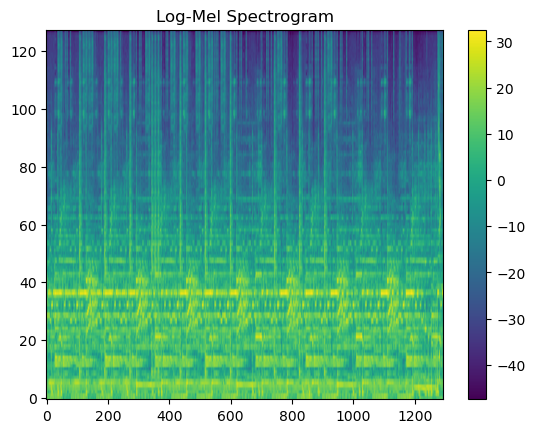

In [7]:
plt.imshow(mel, aspect="auto", origin="lower")
plt.colorbar()
plt.title("Log-Mel Spectrogram")
plt.show()

In [8]:
def slice_melspec(spec, token_width=45, stride=15):
    T = spec.shape[1]
    tokens = [
        np.pad(
            spec[:, i:i+token_width],
            ((0, 0), (0, max(0, token_width - spec[:, i:i+token_width].shape[1]))),
            mode='constant'
        )
        for i in range(0, T, stride)
    ]

    return tokens

In [9]:
tokens = slice_melspec(mel, token_width=45, stride=15)
print(f"Number of tokens: {len(tokens)}")
print(f"Single token shape: {tokens[0].shape}")

Number of tokens: 87
Single token shape: (128, 45)


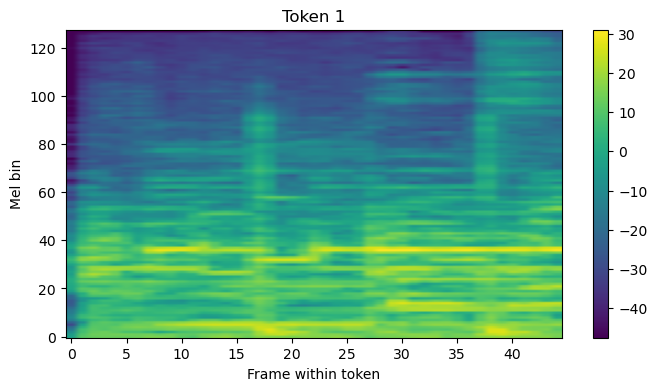

In [10]:
for idx in range(1):
    plt.figure(figsize=(8, 4))
    plt.imshow(tokens[idx], aspect="auto", origin="lower")
    plt.colorbar()
    plt.title(f"Token {idx + 1}")
    plt.xlabel("Frame within token")
    plt.ylabel("Mel bin")
    plt.show()

In [11]:
def token_stats(token):
    return {
        "mean": np.mean(token),
        "std": np.std(token),
        "max": np.max(token),
        "min": np.min(token),
    }

In [12]:
for i in tokens:
    print(token_stats(i))

{'mean': -8.167123, 'std': 16.843699, 'max': 30.963276, 'min': -47.47081}
{'mean': -5.466279, 'std': 15.497111, 'max': 31.548187, 'min': -47.47081}
{'mean': -4.9169507, 'std': 14.922067, 'max': 31.548187, 'min': -47.47081}
{'mean': -6.0692606, 'std': 15.108747, 'max': 31.548187, 'min': -47.47081}
{'mean': -7.599001, 'std': 16.085188, 'max': 29.107529, 'min': -47.47081}
{'mean': -6.165298, 'std': 15.976438, 'max': 29.948963, 'min': -47.47081}
{'mean': -4.556018, 'std': 14.845177, 'max': 31.761154, 'min': -47.47081}
{'mean': -3.0970988, 'std': 13.302995, 'max': 31.761154, 'min': -47.47081}
{'mean': -4.656932, 'std': 13.823632, 'max': 31.761154, 'min': -44.31826}
{'mean': -6.736018, 'std': 15.224188, 'max': 28.508806, 'min': -47.47081}
{'mean': -6.548875, 'std': 15.868803, 'max': 29.461813, 'min': -47.47081}
{'mean': -5.3621235, 'std': 15.349569, 'max': 31.209435, 'min': -47.47081}
{'mean': -2.9591627, 'std': 13.840534, 'max': 31.209435, 'min': -47.47081}
{'mean': -3.1673903, 'std': 12.78

In [13]:
def plot_hist(domain):
    plt.figure(figsize=(8, 5))
    plt.hist(domain, bins=20)
    plt.title("Distribution of Token Mean Energy")
    plt.xlabel("Mean dB")
    plt.ylabel("Frequency")
    plt.show()

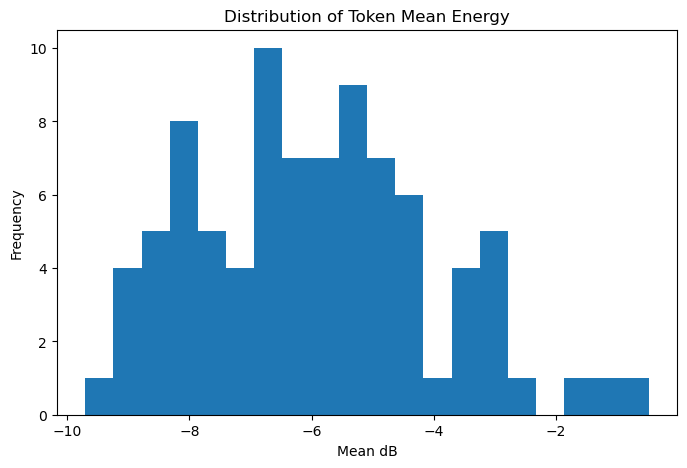

In [14]:
means = [np.mean(t) for t in tokens]
plot_hist(means)

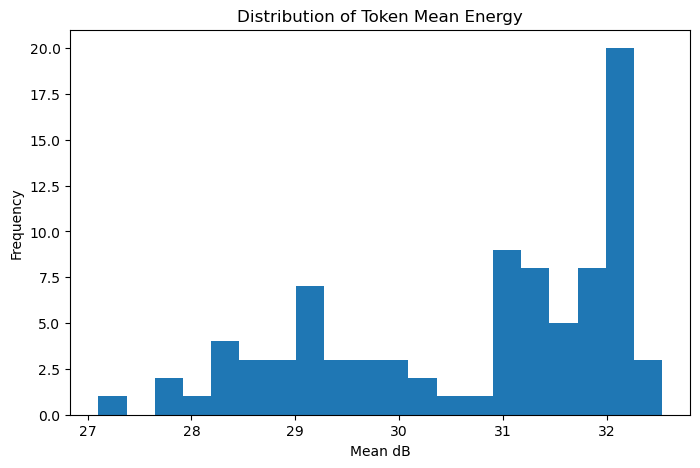

In [15]:
maxs = [np.max(t) for t in tokens]
plot_hist(maxs)

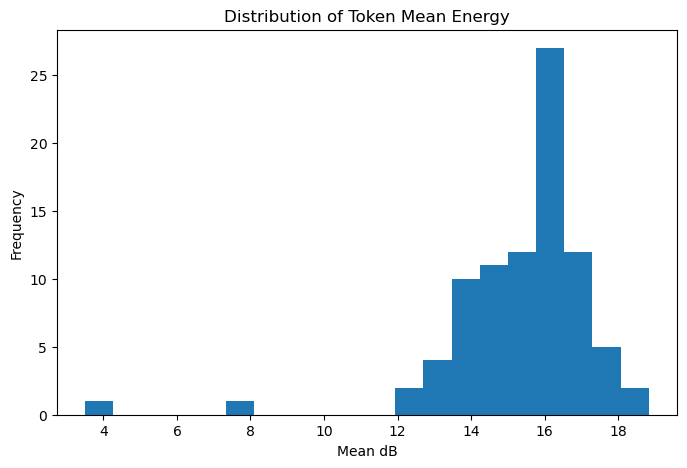

In [16]:
stds = [np.std(t) for t in tokens]
plot_hist(stds)

## Dataset Checking

In [21]:
data = np.load("../../datasets/fma/mel_vad_dataset.npz", allow_pickle=True)

spectrograms = data["spectrograms"]
labels = data["labels"]
track_ids = data["track_ids"]
failed = data["failed"]

In [27]:
print("Total spectrograms:", len(spectrograms))
print("Total labels:", len(labels))
print("Total track_ids:", len(track_ids))
print("Total failed:", len(failed))

Total spectrograms: 27909
Total labels: 27909
Total track_ids: 27909
Total failed: 78665


In [28]:
print(data.files)

['spectrograms', 'labels', 'track_ids', 'failed']


In [29]:
config = configparser.ConfigParser()
config.read("config.cfg")

['config.cfg']

In [30]:
token_width = config.getint("tokenizer", "token_width")
stride = config.getint("tokenizer", "stride")
max_tokens = config.getint("tokenizer", "max_tokens")
random_crop = config.getboolean("tokenizer", "random_crop")


In [ ]:
token_seqs = []

for m in spectrograms:
    mel_tensor = torch.tensor(m, dtype=torch.float32)

    tokens = mel_tokenizer(
        mel=mel_tensor,
        token_width=token_width,
        stride=stride,
        max_tokens=max_tokens,
        random_crop=random_crop
    )

    token_seqs.append(tokens.numpy())


In [ ]:
print(type(token_seqs))
print(len(token_seqs))          # number of tracks

first = tokens[0]
print(type(first))
print(first.shape)
print(first.dtype)

<class 'list'>
27909
<class 'torch.Tensor'>
torch.Size([128, 45])
torch.float32
